# Credit Card Usage Segmentation (Unsupervised Learning)
Goal: segment credit card customers by spending and payment behaviour, compare
K-Means, Hierarchical, Gaussian Mixture and DBSCAN, and turn the result into business insight.

In [13]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("outputs", exist_ok=True)

## 1. Load data

In [14]:
df = pd.read_csv("Customer Data.csv")
print("Shape:", df.shape)
display(df.head())
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])

Shape: (8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12



Missing values:
 CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64


## 2. Clean data
`CUST_ID` is only an identifier, so it is not used for clustering.
Only `CREDIT_LIMIT` (1 row) and `MINIMUM_PAYMENTS` (313 rows) have missing values; filled with the median, which is robust to outliers.

In [15]:
X = df.drop(columns="CUST_ID").copy()
for col in ["MINIMUM_PAYMENTS", "CREDIT_LIMIT"]:
    X[col] = X[col].fillna(X[col].median())
df[X.columns] = X  # keep the cleaned values in the main table too
print("Missing after cleaning:", int(X.isna().sum().sum()))

Missing after cleaning: 0


## 3. Exploratory data analysis

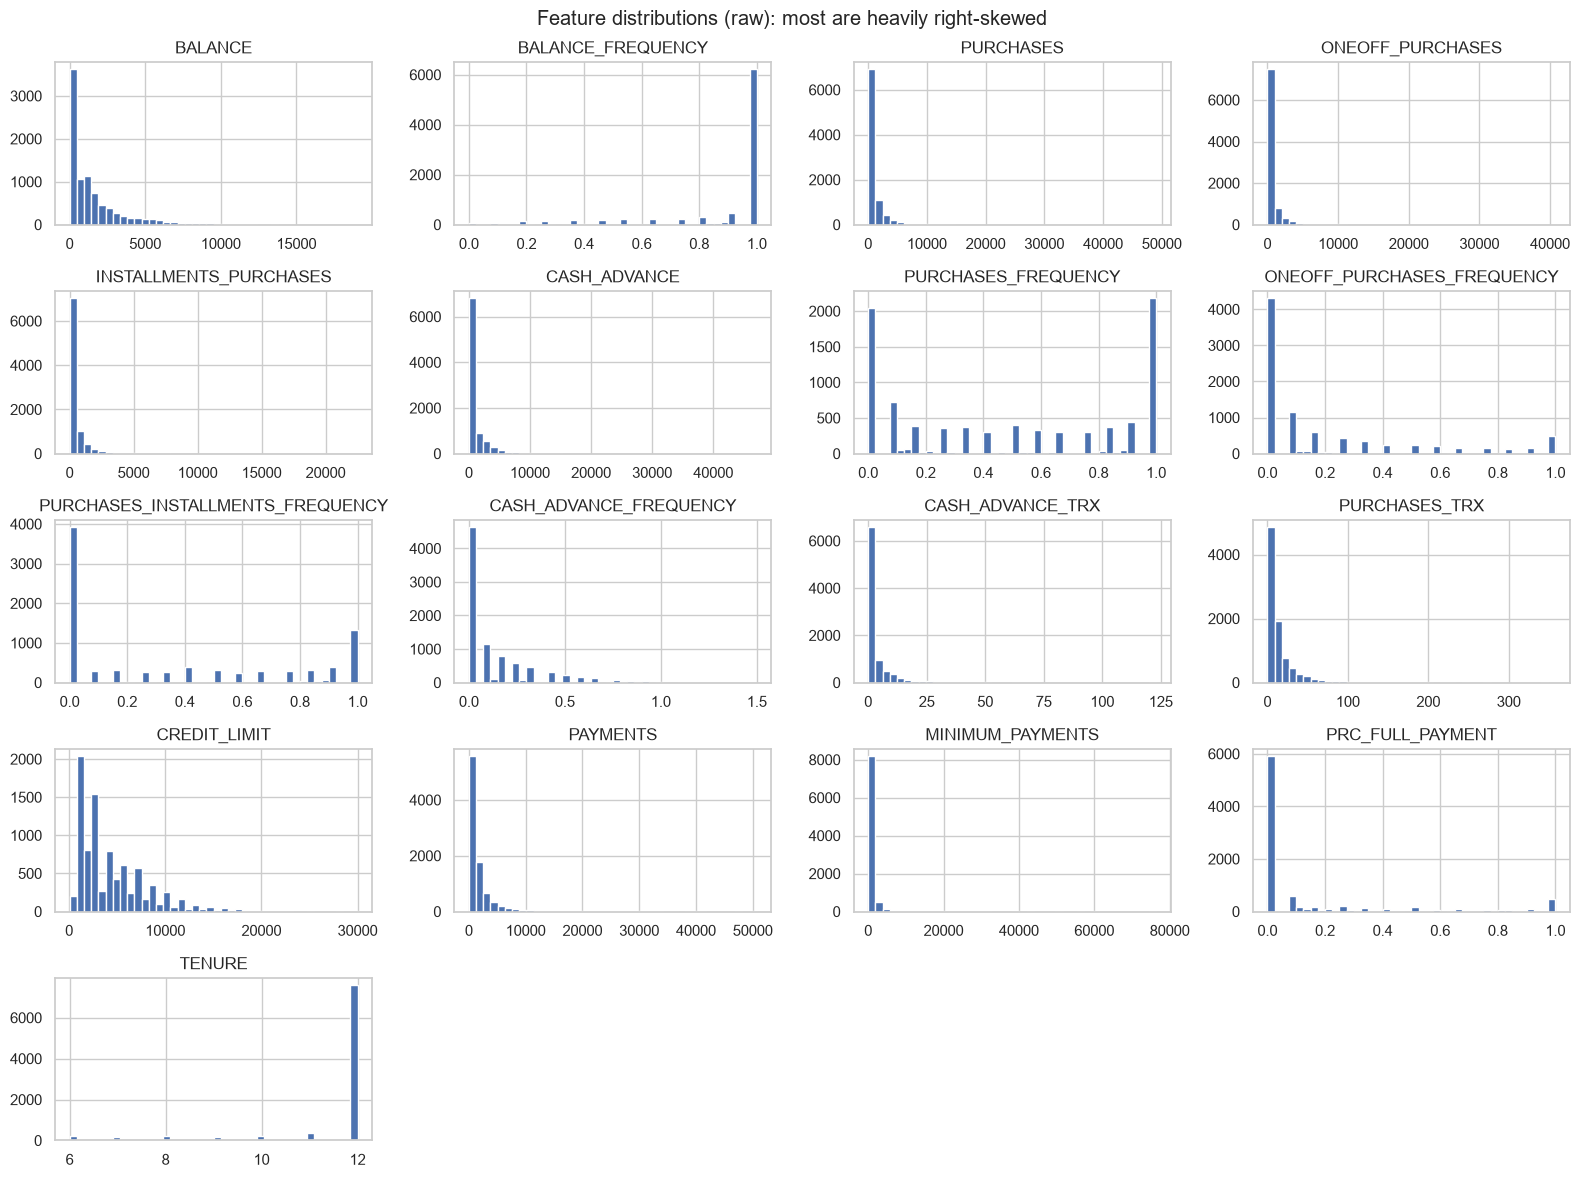

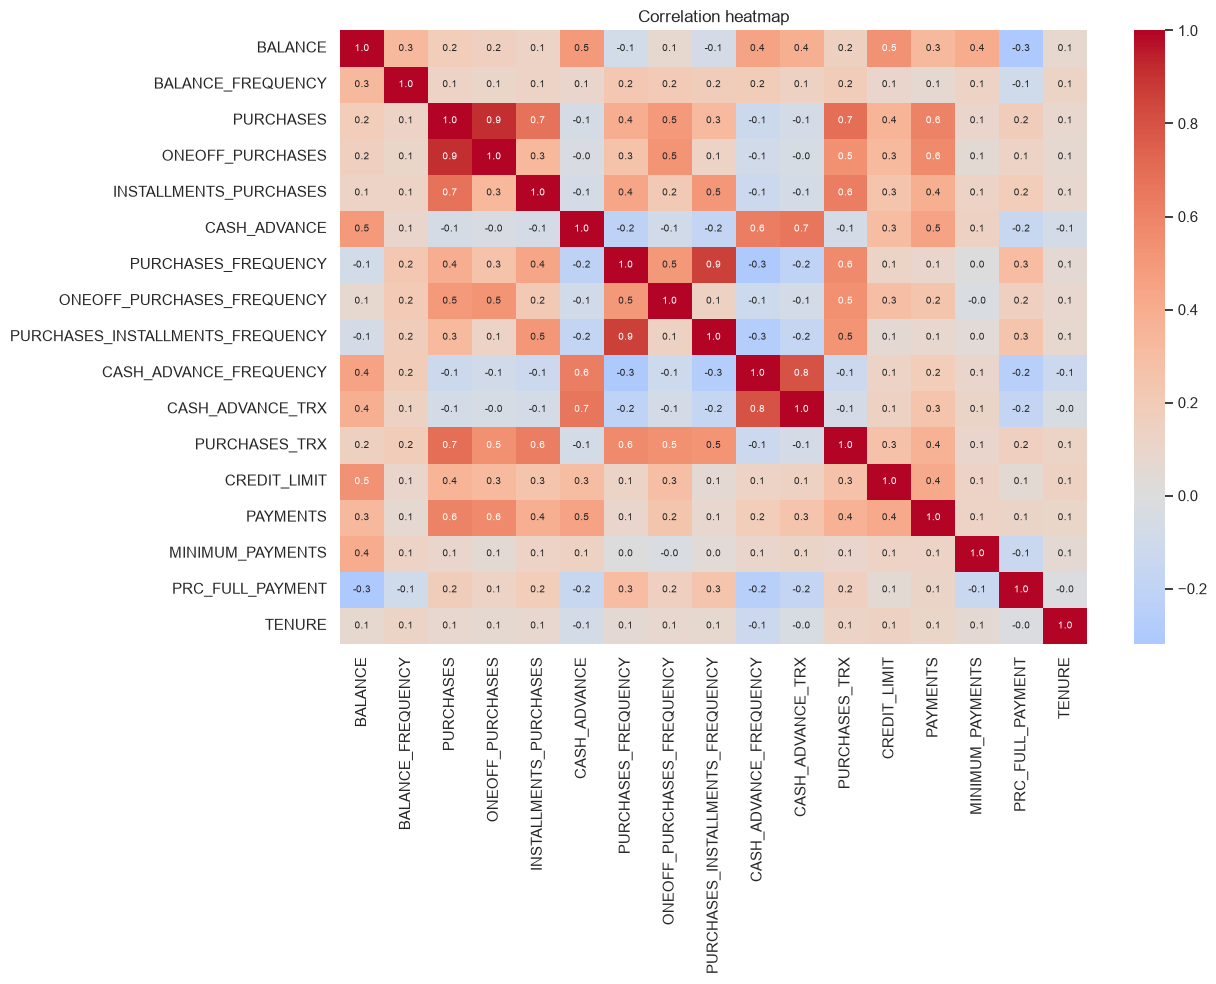

In [16]:
X.hist(bins=40, figsize=(16, 12))
plt.suptitle("Feature distributions (raw): most are heavily right-skewed")
plt.tight_layout()
plt.savefig("outputs/01_distributions.png", dpi=120)
plt.show()

plt.figure(figsize=(13, 10))
sns.heatmap(X.corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("outputs/02_correlation.png", dpi=120)
plt.show()

## 4. Preprocessing
The raw features are very skewed (a few customers spend 50x the average), and K-Means is distance based.
So: `log1p` transform to reduce skew, then `StandardScaler` so every feature has equal weight.
PCA to 2-D is used **only for plotting**.

In [17]:
X_log = np.log1p(X)
X_scaled = StandardScaler().fit_transform(X_log)

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print("Variance explained by 2 PCs: %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

Variance explained by 2 PCs: 56.5%


## 5. Choosing the number of clusters (K-Means)
Elbow + silhouette + Davies-Bouldin. Inertia falls steadily with no sharp elbow, and silhouette is highest at k=2
(a basic "active vs inactive" split), which is too coarse to be useful for marketing.
k=5 gives clearly distinct, interpretable business segments, so **k = 5** is used (a judgement, not a sharp statistical optimum).

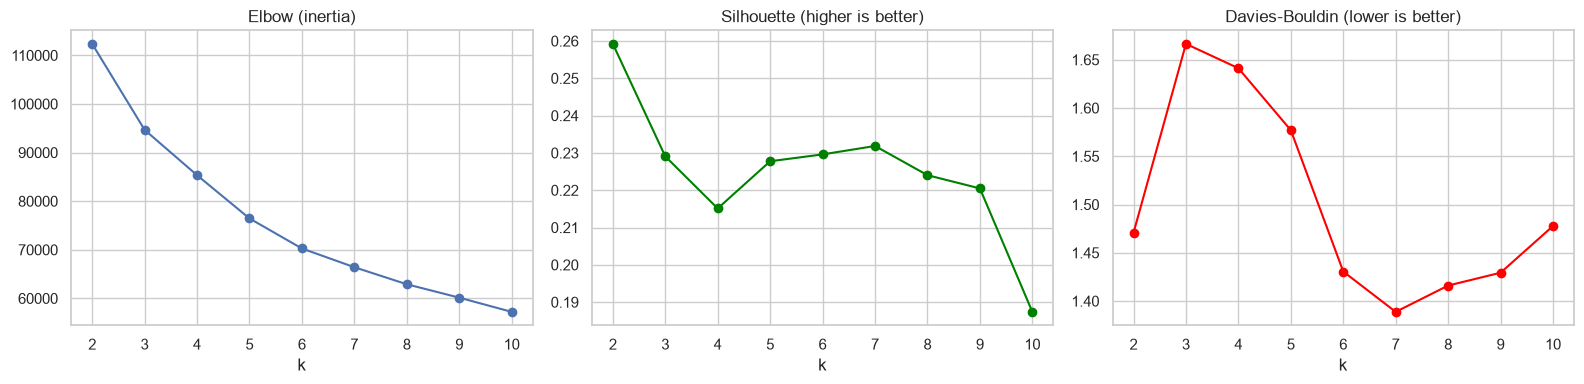

In [18]:
ks = range(2, 11)
inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))
    dbi.append(davies_bouldin_score(X_scaled, km.labels_))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)")
ax[1].plot(ks, sil, "o-", color="green"); ax[1].set_title("Silhouette (higher is better)")
ax[2].plot(ks, dbi, "o-", color="red"); ax[2].set_title("Davies-Bouldin (lower is better)")
for a in ax: a.set_xlabel("k")
plt.tight_layout()
plt.savefig("outputs/03_choose_k.png", dpi=120)
plt.show()

## 6. Fit the four algorithms

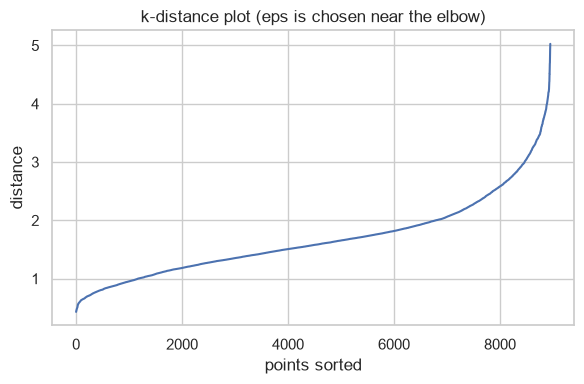

In [19]:
K = 5
models = {}
models["K-Means"] = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled)
models["Hierarchical (Ward)"] = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X_scaled)
models["Gaussian Mixture"] = GaussianMixture(n_components=K, random_state=RANDOM_STATE, n_init=3).fit_predict(X_scaled)

# DBSCAN: min_samples = 2 x n_features; eps read from the k-distance plot
min_samples = 2 * X_scaled.shape[1]
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled).kneighbors(X_scaled)
plt.figure(figsize=(6, 4))
plt.plot(np.sort(dist[:, -1]))
plt.title("k-distance plot (eps is chosen near the elbow)")
plt.ylabel("distance"); plt.xlabel("points sorted")
plt.tight_layout()
plt.savefig("outputs/04_dbscan_kdistance.png", dpi=120)
plt.show()
models["DBSCAN"] = DBSCAN(eps=2.5, min_samples=min_samples).fit_predict(X_scaled)

## 7. Comparing the algorithms
DBSCAN noise points (label -1) are excluded from its metrics.

,Algorithm,Clusters,Noise points,Silhouette (higher),Davies-Bouldin (lower),Calinski-Harabasz (higher)
0,K-Means,5,0,0.228,1.577,2214.798
1,Hierarchical (Ward),5,0,0.179,1.714,1646.833
2,Gaussian Mixture,5,0,0.186,1.688,1730.129
3,DBSCAN,2,319,0.290,0.909,150.614


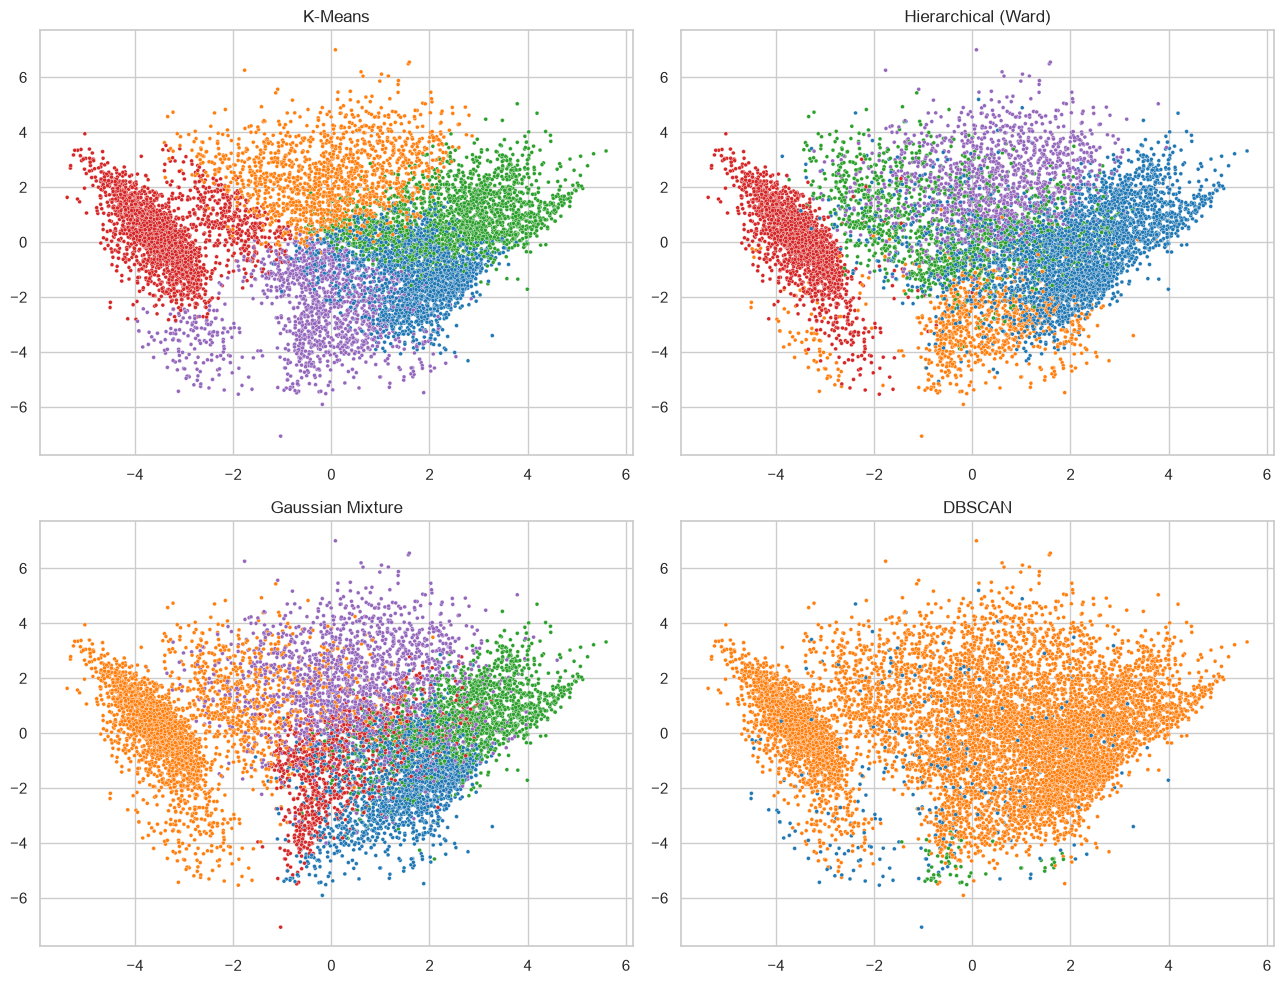

In [20]:
rows = []
for name, labels in models.items():
    mask = labels != -1
    n_clusters = len(set(labels[mask]))
    rows.append([name, n_clusters, int((~mask).sum()),
                 silhouette_score(X_scaled[mask], labels[mask]),
                 davies_bouldin_score(X_scaled[mask], labels[mask]),
                 calinski_harabasz_score(X_scaled[mask], labels[mask])])
comparison = pd.DataFrame(rows, columns=["Algorithm", "Clusters", "Noise points",
                          "Silhouette (higher)", "Davies-Bouldin (lower)",
                          "Calinski-Harabasz (higher)"]).round(3)
display(comparison)
comparison.to_csv("outputs/algorithm_comparison.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, labels) in zip(axes.ravel(), models.items()):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette="tab10", s=8, ax=ax, legend=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig("outputs/05_algorithm_scatter.png", dpi=120)
plt.show()

**Reading the table**
- **K-Means** has the best Calinski-Harabasz and the best silhouette of the three 5-cluster models, assigns every customer, and is easy to explain, so it is the **final model**.
- **Hierarchical** and **Gaussian Mixture** give similar but slightly weaker separation.
- **DBSCAN** scores well only because it finds just 2 big groups and labels 319 customers as noise. Credit card data is a continuous cloud with no clear density gaps, so DBSCAN is not suitable for 5 business segments (but it is useful for spotting unusual customers).

## 8. Final model: K-Means segments and profiles

In [21]:
df["Segment"] = models["K-Means"]

profile = X.assign(Segment=df["Segment"]).groupby("Segment").mean().round(2)
profile["Customers"] = df["Segment"].value_counts().sort_index()
profile["Share %"] = (profile["Customers"] / len(df) * 100).round(1)
display(profile.T)
profile.to_csv("outputs/segment_profile.csv")

Segment,0,1,2,3,4
BALANCE,425.07,3273.68,1479.34,2294.34,251.56
BALANCE_FREQUENCY,0.90,0.97,0.97,0.94,0.52
PURCHASES,614.91,1376.67,2768.95,28.16,323.63
ONEOFF_PURCHASES,32.63,810.35,1895.52,25.87,268.44
INSTALLMENTS_PURCHASES,583.20,566.55,873.51,2.34,55.45
CASH_ADVANCE,32.23,2622.00,45.62,2022.11,130.37
PURCHASES_FREQUENCY,0.79,0.68,0.82,0.02,0.21
ONEOFF_PURCHASES_FREQUENCY,0.02,0.30,0.59,0.02,0.11
PURCHASES_INSTALLMENTS_FREQUENCY,0.75,0.49,0.52,0.00,0.09
CASH_ADVANCE_FREQUENCY,0.01,0.34,0.01,0.28,0.02


## 9. Naming the segments
Segment numbers can change if the random seed changes. The names below match the profile with `RANDOM_STATE = 42`.
If you see a different profile, re-check the table above and rename accordingly.

In [22]:
segment_names = {
    0: "Installment Buyers",        # low balance, frequent installment purchases, almost no cash advance
    1: "High-Balance Revolvers",    # high balance + cash advance + purchases, rarely pays in full
    2: "Premium Big Spenders",      # highest purchases (one-off), high limit, pays well
    3: "Cash-Advance Dependents",   # almost no purchases, lives on cash advances
    4: "Dormant / Low Activity",    # low balance, low frequency of everything
}
df["Segment_Name"] = df["Segment"].map(segment_names)
print(df["Segment_Name"].value_counts())

Segment_Name
Cash-Advance Dependents    2333
Premium Big Spenders       1933
Installment Buyers         1897
High-Balance Revolvers     1417
Dormant / Low Activity     1370
Name: count, dtype: int64


## 10. Visualising the segments

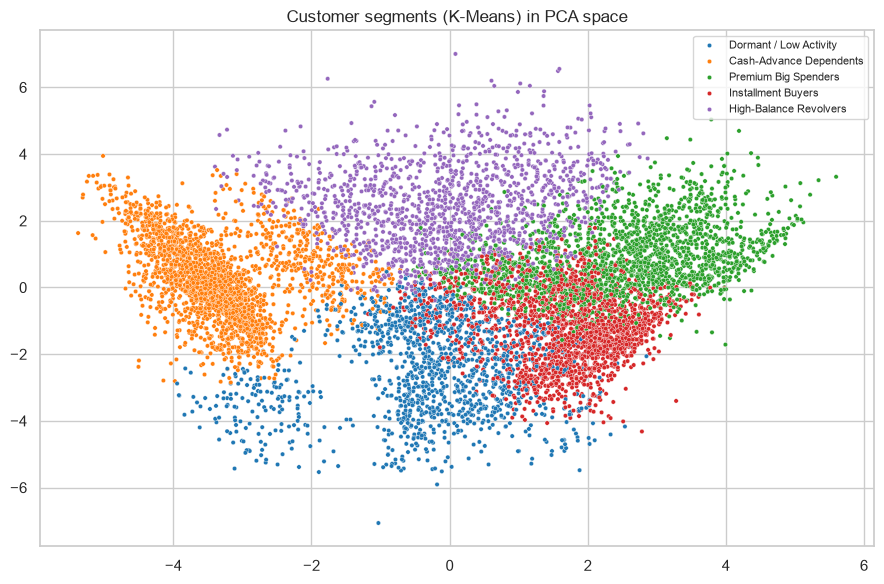

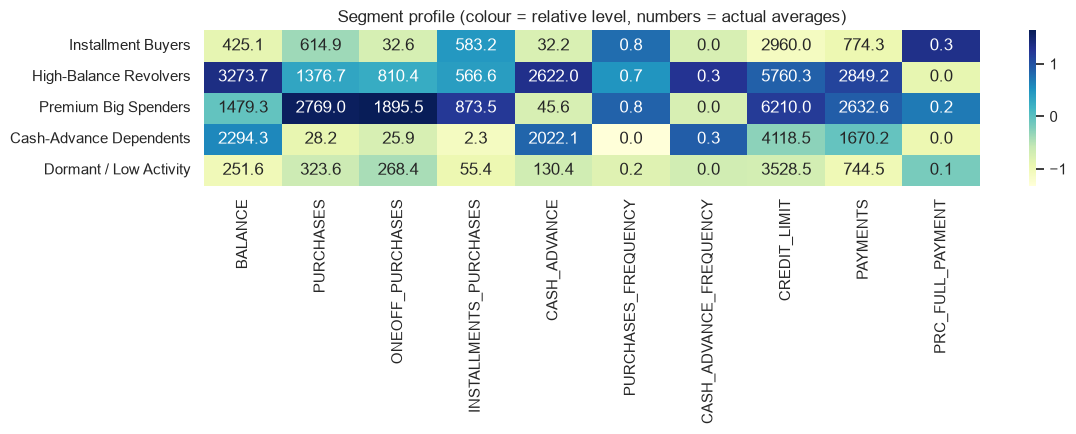

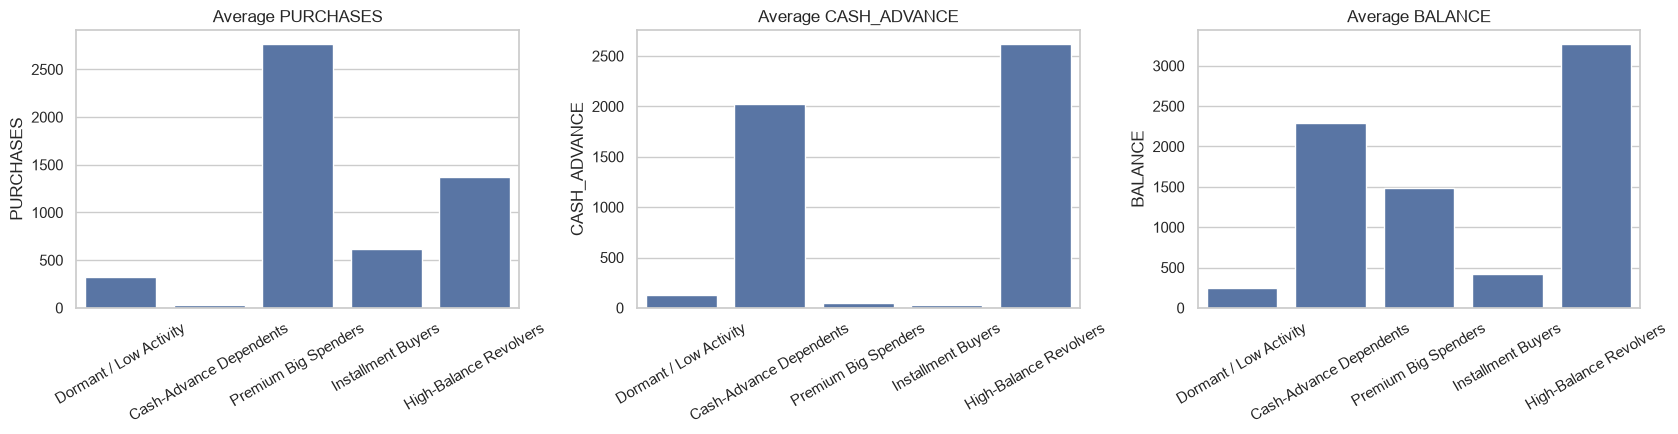

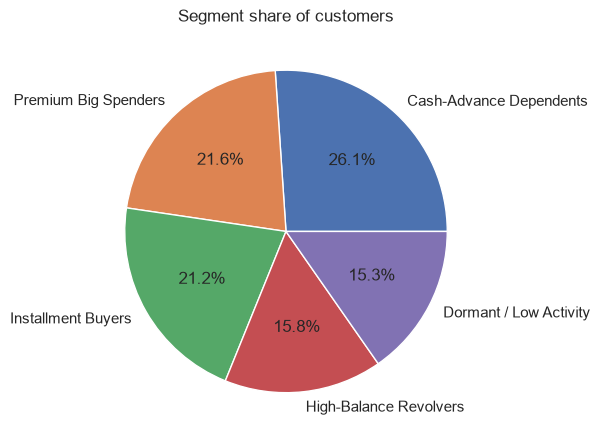

In [23]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df["Segment_Name"], palette="tab10", s=10)
plt.title("Customer segments (K-Means) in PCA space")
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.savefig("outputs/06_segments_pca.png", dpi=120)
plt.show()

key = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
       "PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
z = profile[key]
z = (z - z.mean()) / z.std()
z.index = [segment_names[i] for i in z.index]
annot = profile[key].round(1)
annot.index = z.index
plt.figure(figsize=(12, 4.5))
sns.heatmap(z, annot=annot, fmt="", cmap="YlGnBu")
plt.title("Segment profile (colour = relative level, numbers = actual averages)")
plt.tight_layout()
plt.savefig("outputs/07_segment_heatmap.png", dpi=120)
plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, col in zip(ax, ["PURCHASES", "CASH_ADVANCE", "BALANCE"]):
    sns.barplot(x="Segment_Name", y=col, data=X.assign(Segment_Name=df["Segment_Name"]), ax=a, errorbar=None)
    a.set_title("Average " + col)
    a.tick_params(axis="x", rotation=30)
    a.set_xlabel("")
plt.tight_layout()
plt.savefig("outputs/08_segment_bars.png", dpi=120)
plt.show()

plt.figure(figsize=(6, 6))
df["Segment_Name"].value_counts().plot.pie(autopct="%1.1f%%", ylabel="")
plt.title("Segment share of customers")
plt.tight_layout()
plt.savefig("outputs/09_segment_share.png", dpi=120)
plt.show()

## 11. Business insights
| Segment | Behaviour | Marketing action | Risk view |
|---|---|---|---|
| Premium Big Spenders | Highest purchases, high limit, pays well | Rewards, premium cards, limit increases | Low |
| Installment Buyers | Frequent installment purchases, no cash advance | EMI offers, cashback on instalments | Low to medium |
| High-Balance Revolvers | High balance, cash advance and purchases, rarely pays in full | Balance-transfer and repayment plans | High: monitor closely |
| Cash-Advance Dependents | Almost no purchases, relies on cash advances | Financial counselling, restructure, cap advances | Highest: early-warning list |
| Dormant / Low Activity | Low balance, rare usage | Re-activation campaigns, welcome offers | Low (churn risk) |

In [24]:
df.to_csv("outputs/customers_with_segments.csv", index=False)
print("Saved to outputs/")

Saved to outputs/


# Part 2: Course tools applied to the project
Each section below maps to a session in the academic calendar:
SQL (sessions 7-8), Statistics & Hypothesis Testing (15-16), Decision Trees & Ensembles (26),
Model Evaluation & Validation (27), Logistic Regression, SVM and KNN (25, 29), Excel (3-4), Power BI (19), Gradio deployment (40).

## 12. SQL: query the segments (Intro SQL & Advanced SQL)
The labelled customers are loaded into a SQLite database and analysed with SQL (aggregation, CASE, window functions).

In [25]:
import sqlite3
con = sqlite3.connect("outputs/credit_card.db")
df.to_sql("customers", con, if_exists="replace", index=False)

q1 = """
SELECT Segment_Name,
       COUNT(*)                          AS customers,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM customers), 1) AS share_pct,
       ROUND(AVG(BALANCE), 0)            AS avg_balance,
       ROUND(AVG(PURCHASES), 0)          AS avg_purchases,
       ROUND(AVG(CASH_ADVANCE), 0)       AS avg_cash_advance,
       ROUND(AVG(CREDIT_LIMIT), 0)       AS avg_limit
FROM customers
GROUP BY Segment_Name
ORDER BY customers DESC;
"""
display(pd.read_sql(q1, con))

# Credit utilisation per segment (balance as % of limit) using CASE for risk bands
q2 = """
SELECT Segment_Name,
       SUM(CASE WHEN BALANCE / CREDIT_LIMIT > 0.8 THEN 1 ELSE 0 END) AS high_utilisation_customers,
       SUM(CASE WHEN PRC_FULL_PAYMENT = 0 THEN 1 ELSE 0 END)         AS never_pay_in_full,
       ROUND(AVG(PAYMENTS / NULLIF(MINIMUM_PAYMENTS, 0)), 2)          AS payments_to_minimum_ratio
FROM customers
GROUP BY Segment_Name;
"""
display(pd.read_sql(q2, con))

# Window function: top 3 highest-balance customers in each segment
q3 = """
SELECT * FROM (
  SELECT CUST_ID, Segment_Name, ROUND(BALANCE, 0) AS BALANCE,
         RANK() OVER (PARTITION BY Segment_Name ORDER BY BALANCE DESC) AS rnk
  FROM customers)
WHERE rnk <= 3 ORDER BY Segment_Name, rnk;
"""
display(pd.read_sql(q3, con))
con.close()

,Segment_Name,customers,share_pct,avg_balance,avg_purchases,avg_cash_advance,avg_limit
0,Cash-Advance Dependents,2333,26.1,2294.0,28.0,2022.0,4119.0
1,Premium Big Spenders,1933,21.6,1479.0,2769.0,46.0,6210.0
2,Installment Buyers,1897,21.2,425.0,615.0,32.0,2960.0
3,High-Balance Revolvers,1417,15.8,3274.0,1377.0,2622.0,5760.0
4,Dormant / Low Activity,1370,15.3,252.0,324.0,130.0,3529.0


,Segment_Name,high_utilisation_customers,never_pay_in_full,payments_to_minimum_ratio
0,Cash-Advance Dependents,852,1922,4.12
1,Dormant / Low Activity,87,1002,22.27
2,High-Balance Revolvers,417,1122,3.61
3,Installment Buyers,258,795,9.95
4,Premium Big Spenders,198,1062,8.78


,CUST_ID,Segment_Name,BALANCE,rnk
0,C10914,Cash-Advance Dependents,14581.0,1
1,C10130,Cash-Advance Dependents,14224.0,2
2,C16079,Cash-Advance Dependents,13777.0,3
3,C13603,Dormant / Low Activity,3443.0,1
4,C14159,Dormant / Low Activity,3298.0,2
5,C18985,Dormant / Low Activity,2856.0,3
6,C15642,High-Balance Revolvers,16305.0,1
7,C16812,High-Balance Revolvers,16259.0,2
8,C15429,High-Balance Revolvers,16116.0,3
9,C11146,Installment Buyers,8115.0,1


## 13. Statistics: are the segments really different? (Statistics & Hypothesis Testing)
H0: the feature has the same distribution in all segments. H1: at least one segment differs.
The features are heavily skewed, so the non-parametric **Kruskal-Wallis** test is used instead of ANOVA.
Epsilon-squared is the effect size (how big the difference is, not just whether it exists).

In [26]:
from scipy import stats

test_cols = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
rows = []
n = len(df)
for col in test_cols:
    groups = [g[col].values for _, g in df.groupby("Segment")]
    h, p = stats.kruskal(*groups)
    eps2 = h / (n - 1) if n > 1 else np.nan  # effect size
    rows.append([col, round(h, 1), p, round(eps2, 3), "Reject H0" if p < 0.05 else "Fail to reject H0"])
display(pd.DataFrame(rows, columns=["Feature", "H statistic", "p-value", "Effect size (eps^2)", "Decision (alpha=0.05)"]))

,Feature,H statistic,p-value,Effect size (eps^2),Decision (alpha=0.05)
0,BALANCE,4284.2,0.000000e+00,0.479,Reject H0
1,PURCHASES,6322.0,0.000000e+00,0.706,Reject H0
2,CASH_ADVANCE,6839.9,0.000000e+00,0.764,Reject H0
3,CREDIT_LIMIT,1234.6,4.907932e-266,0.138,Reject H0
4,PAYMENTS,2264.6,0.000000e+00,0.253,Reject H0
5,PRC_FULL_PAYMENT,1304.3,3.913314e-281,0.146,Reject H0


## 14. Decision tree & Random Forest: explain and predict the segments (Decision Trees and Ensembles)
The segments came from unsupervised K-Means. A supervised model trained to predict them shows
(a) which features define each segment and (b) how reliably a new customer can be assigned a segment.

Decision tree (depth 4) test accuracy: 0.885
Random forest test accuracy:           0.955


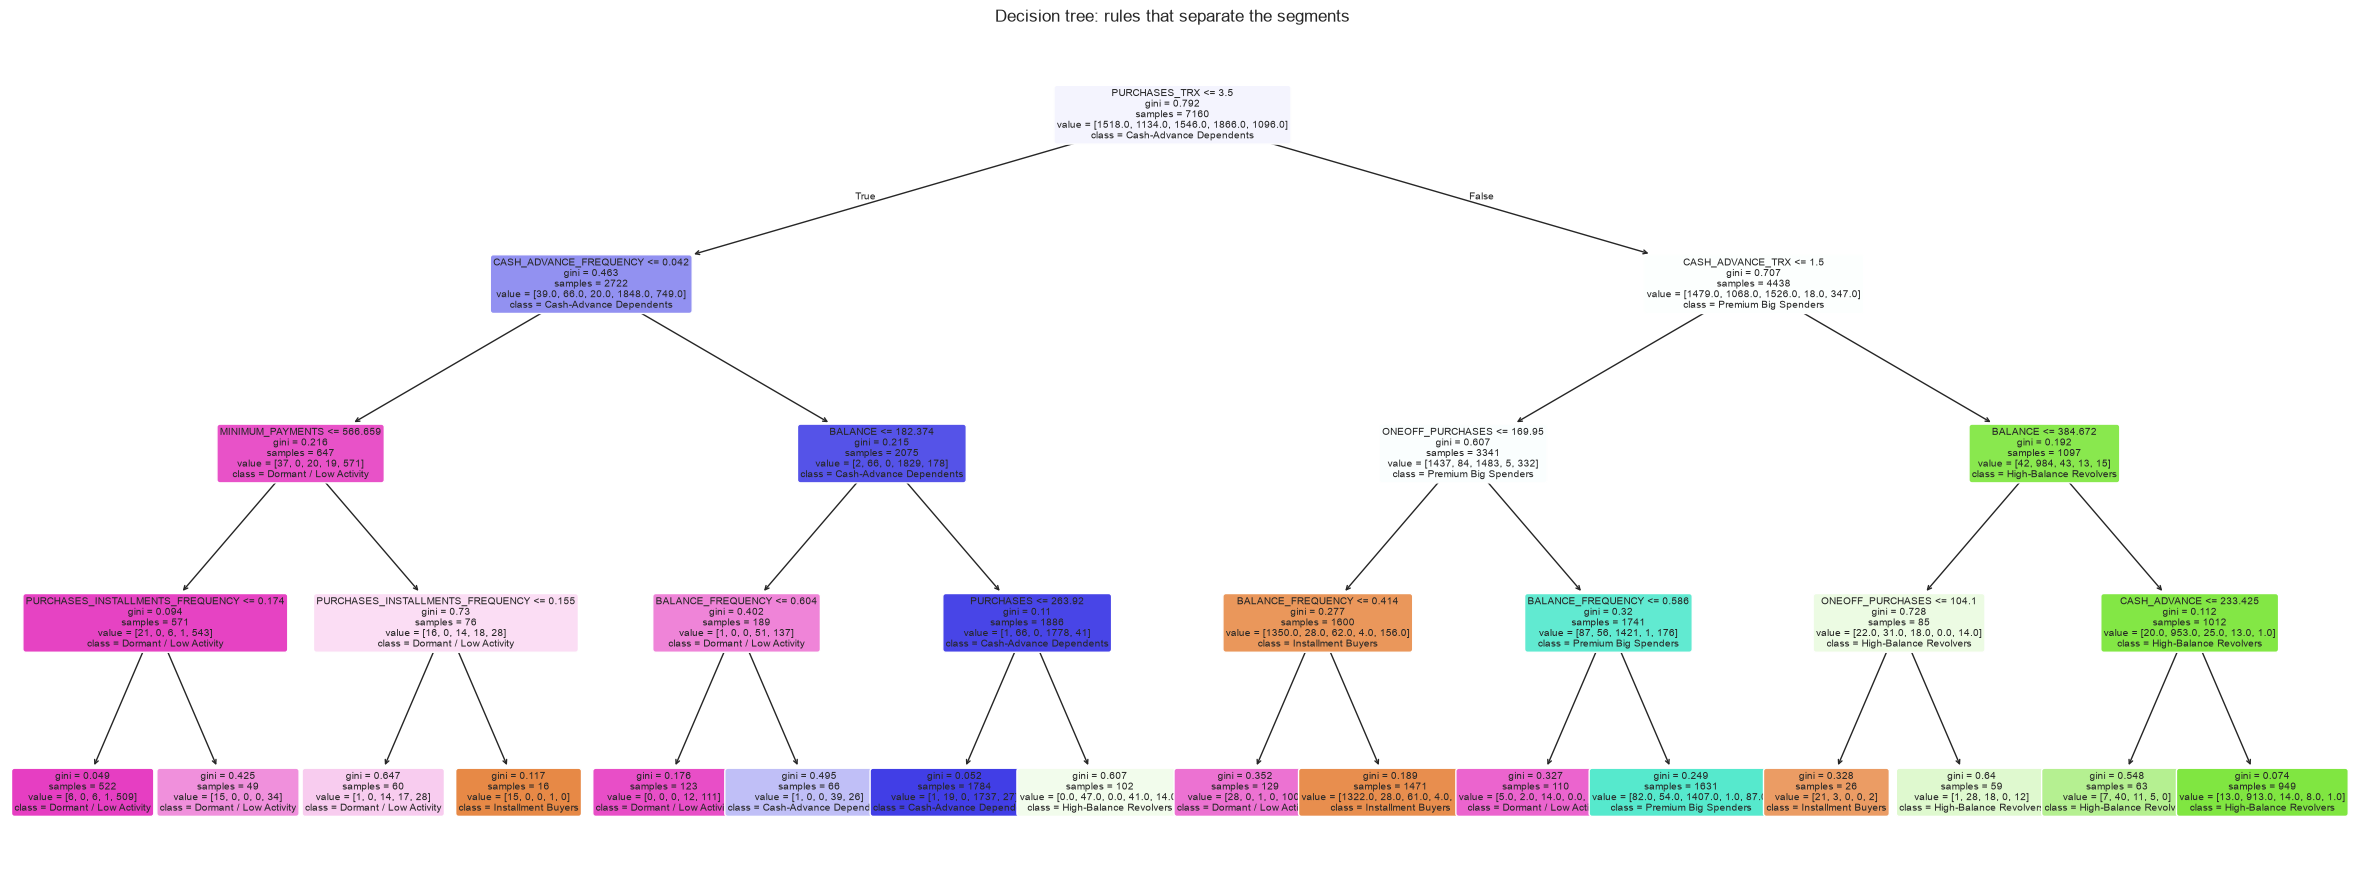

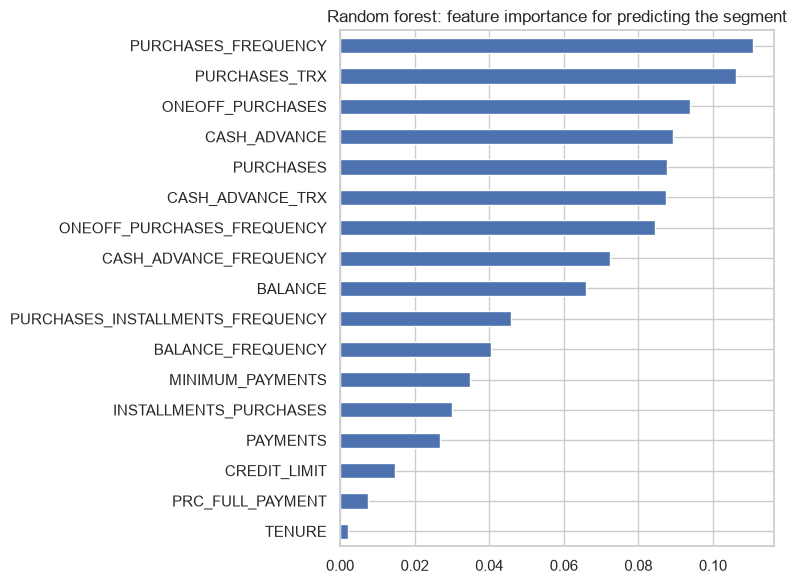

In [27]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

y = df["Segment"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

tree = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE).fit(X_tr, y_tr)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1).fit(X_tr, y_tr)
print("Decision tree (depth 4) test accuracy: %.3f" % accuracy_score(y_te, tree.predict(X_te)))
print("Random forest test accuracy:           %.3f" % accuracy_score(y_te, rf.predict(X_te)))

plt.figure(figsize=(30, 11))
plot_tree(tree, feature_names=X.columns, class_names=[segment_names[i] for i in sorted(segment_names)],
          filled=True, rounded=True, fontsize=7)
plt.title("Decision tree: rules that separate the segments")
plt.savefig("outputs/10_decision_tree.png", dpi=110, bbox_inches="tight")
plt.show()

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 6))
imp.plot.barh()
plt.title("Random forest: feature importance for predicting the segment")
plt.tight_layout()
plt.savefig("outputs/11_feature_importance.png", dpi=120)
plt.show()

## 15. Model evaluation & validation (Model Evaluation and Validation Techniques)
Two checks: (1) 5-fold cross-validation of the segment predictor, (2) stability of the clustering itself
(re-run K-Means with different seeds and compare with Adjusted Rand Index; 1.0 = identical).

Random forest 5-fold CV accuracy: 0.959 +/- 0.004

Classification report (test set):
                         precision    recall  f1-score   support

     Installment Buyers       0.95      0.95      0.95       379
 High-Balance Revolvers       0.93      0.96      0.94       283
   Premium Big Spenders       0.97      0.95      0.96       387
Cash-Advance Dependents       0.98      0.98      0.98       467
 Dormant / Low Activity       0.93      0.92      0.93       274

               accuracy                           0.96      1790
              macro avg       0.95      0.95      0.95      1790
           weighted avg       0.96      0.96      0.96      1790



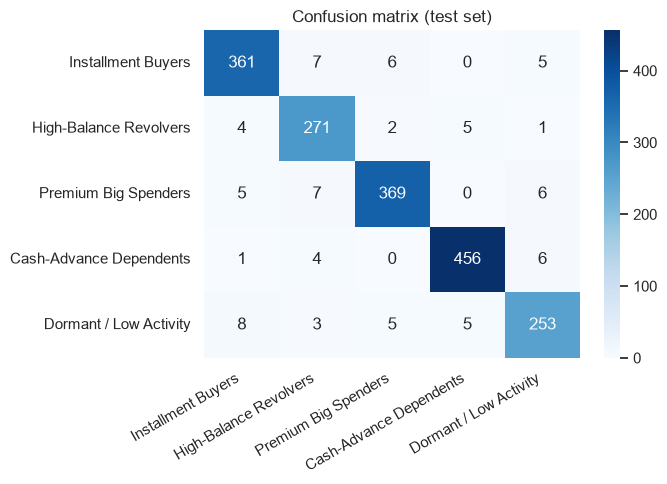

Clustering stability (ARI vs the final model, 10 other seeds): mean 0.997, min 0.993


In [28]:
from sklearn.metrics import adjusted_rand_score

cv = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
                     X, y, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
print("Random forest 5-fold CV accuracy: %.3f +/- %.3f" % (cv.mean(), cv.std()))

print("\nClassification report (test set):")
print(classification_report(y_te, rf.predict(X_te), target_names=[segment_names[i] for i in sorted(segment_names)]))

plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(y_te, rf.predict(X_te)), annot=True, fmt="d", cmap="Blues",
            xticklabels=[segment_names[i] for i in sorted(segment_names)],
            yticklabels=[segment_names[i] for i in sorted(segment_names)])
plt.title("Confusion matrix (test set)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("outputs/12_confusion_matrix.png", dpi=120)
plt.show()

base = models["K-Means"]
aris = [adjusted_rand_score(base, KMeans(K, n_init=10, random_state=s).fit_predict(X_scaled)) for s in range(1, 11)]
print("Clustering stability (ARI vs the final model, 10 other seeds): mean %.3f, min %.3f" % (np.mean(aris), np.min(aris)))

## 16. Comparing supervised classifiers: Logistic Regression, SVM, KNN, Random Forest (Logistic Regression, SVM and KNN sessions)
The same question as section 14: can a model predict the segment of a customer from card usage?
Here four classifiers are compared on the same train/test split and with 5-fold cross-validation.
Logistic Regression, SVM and KNN are distance or scale sensitive, so they use the log-transformed and scaled features.
Precision, recall and F1 (macro average) treat all five segments equally.

,Classifier,Test accuracy,Precision (macro),Recall (macro),F1 (macro),5-fold CV accuracy
0,Logistic Regression,0.996,0.996,0.996,0.996,0.994
1,SVM (RBF kernel),0.977,0.974,0.975,0.975,0.981
2,KNN (k=7),0.947,0.948,0.941,0.944,0.945
3,Random Forest,0.953,0.950,0.950,0.950,0.960


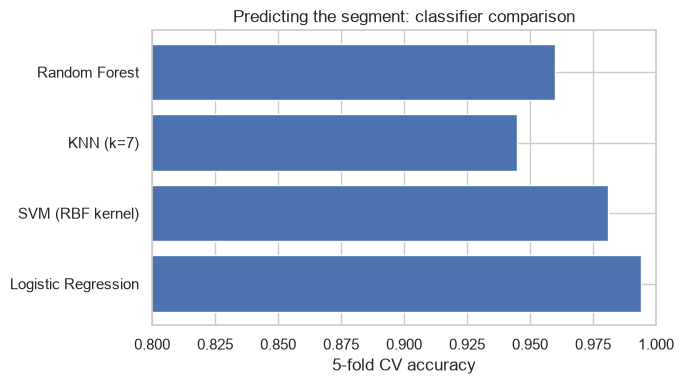

In [29]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import precision_recall_fscore_support

Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_scaled, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
classifiers = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "SVM (RBF kernel)": SVC(kernel="rbf", random_state=RANDOM_STATE),
    "KNN (k=7)": KNeighborsClassifier(n_neighbors=7),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
}
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, clf in classifiers.items():
    clf.fit(Xs_tr, ys_tr)
    pred = clf.predict(Xs_te)
    p, r, f, _ = precision_recall_fscore_support(ys_te, pred, average="macro")
    cvs = cross_val_score(clf, X_scaled, y, cv=skf)
    rows.append([name, round(accuracy_score(ys_te, pred), 3), round(p, 3), round(r, 3), round(f, 3), round(cvs.mean(), 3)])
clf_compare = pd.DataFrame(rows, columns=["Classifier", "Test accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "5-fold CV accuracy"])
display(clf_compare)
clf_compare.to_csv("outputs/classifier_comparison.csv", index=False)

plt.figure(figsize=(7, 4))
plt.barh(clf_compare["Classifier"], clf_compare["5-fold CV accuracy"])
plt.xlim(0.8, 1.0)
plt.xlabel("5-fold CV accuracy")
plt.title("Predicting the segment: classifier comparison")
plt.tight_layout()
plt.savefig("outputs/13_classifier_comparison.png", dpi=120)
plt.show()

**Reading the table.** All four classifiers can predict the segment well, which shows the K-Means segments are clearly separable.
Caveat: the labels were created by K-Means from the same features, so high accuracy shows separability, not agreement with a ground truth.
Logistic Regression scores highest (about 99% in cross-validation) and is also the simplest to explain. This is expected: K-Means draws straight-line boundaries between clusters
in the same scaled feature space, so a linear model can recover them almost perfectly. Tree-based models split on one feature at a time, so they approximate those diagonal boundaries slightly less perfectly (about 96%).

# Part 3: Remaining course sessions applied to the project
These sections cover the rest of the academic calendar: Python fundamentals (9-12), Machine Learning and
Multiple Linear Regression (23-24), Time series ARIMA/SARIMA (30), Deep learning (31-32), NLP (33-34)
and Generative AI / LLMs (37-39).
**Honest note:** the credit card dataset has no dates and no text. Where a session needs time or text, the section says
clearly how that input was created, so it is a demonstration of the method and not a finding about real customers.

## 17. Python fundamentals applied (Python Basics, Loops/Functions/Error handling, Lists/Tuples, Dictionaries/Sets)
Small, clear examples using the project data: a function with error handling, loops, a tuple, lists, a dictionary and sets.

In [30]:
# Function + error handling (sessions 9-10)
def load_customers(path):
    """Load the customer CSV; give a friendly message if the file is missing."""
    try:
        data = pd.read_csv(path)
    except FileNotFoundError:
        print("File not found:", path)
        return None
    return data

print("Missing file ->", load_customers("no_such_file.csv"))
print("Real file    ->", None if load_customers("Customer Data.csv") is None else "loaded OK")

# Tuple (immutable constants) and list (sessions 11)
MONEY_COLUMNS = ("BALANCE", "PURCHASES", "CASH_ADVANCE", "PAYMENTS")     # tuple: should not change
risk_segments = ["Cash-Advance Dependents", "High-Balance Revolvers"]    # list: can grow

# Dictionary + loop + function (sessions 10 and 12)
def describe_segment(name):
    rows = df[df["Segment_Name"] == name]
    return {"segment": name, "customers": len(rows),
            "avg_purchases": round(rows["PURCHASES"].mean(), 1),
            "avg_cash_advance": round(rows["CASH_ADVANCE"].mean(), 1)}

summary = [describe_segment(name) for name in segment_names.values()]      # list comprehension over a dict's values
for item in summary:                                                       # for loop
    flag = "WATCH" if item["segment"] in risk_segments else "ok"
    print(f"{item['segment']:<25} {item['customers']:>5} customers  purchases {item['avg_purchases']:>8}  cash advance {item['avg_cash_advance']:>8}  [{flag}]")

# Sets (session 12): find columns that are in both groups, or only in one
spend_cols = {"PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "PAYMENTS"}
cash_cols = {"CASH_ADVANCE", "CASH_ADVANCE_FREQUENCY", "CASH_ADVANCE_TRX"}
print("Spend columns present in data:", sorted(spend_cols & set(df.columns)))
print("Columns in spend but not cash:", sorted(spend_cols - cash_cols))

File not found: no_such_file.csv
Missing file -> None
Real file    -> loaded OK
Installment Buyers         1897 customers  purchases    614.9  cash advance     32.2  [ok]
High-Balance Revolvers     1417 customers  purchases   1376.7  cash advance   2622.0  [WATCH]
Premium Big Spenders       1933 customers  purchases   2768.9  cash advance     45.6  [ok]
Cash-Advance Dependents    2333 customers  purchases     28.2  cash advance   2022.1  [WATCH]
Dormant / Low Activity     1370 customers  purchases    323.6  cash advance    130.4  [ok]
Spend columns present in data: ['INSTALLMENTS_PURCHASES', 'ONEOFF_PURCHASES', 'PAYMENTS', 'PURCHASES']
Columns in spend but not cash: ['INSTALLMENTS_PURCHASES', 'ONEOFF_PURCHASES', 'PAYMENTS', 'PURCHASES']


## 18. Machine Learning basics and Multiple Linear Regression (Intro to ML & Regression; Multiple Linear Regression & Model Evaluation)
A supervised regression problem on the same customers: **predict how much a customer pays (`PAYMENTS`)** from their balance, purchases,
cash advance, credit limit, purchase frequency and share of months paid in full.
Money values are very skewed, so the target and the money features are log-transformed.
Then a second model adds the **segment** as extra information, to see whether the segments carry information beyond the raw numbers.
Metrics: R-squared (share of variation explained), RMSE and MAE (typical error, on the log scale).

Model A (6 features):   R2 = 0.370, RMSE = 1.207, MAE = 0.794
5-fold CV R2: 0.353


,Coefficient (effect on log PAYMENTS)
BALANCE,0.385
PURCHASES,0.109
CASH_ADVANCE,0.054
CREDIT_LIMIT,0.259
PURCHASES_FREQUENCY,-0.089
PRC_FULL_PAYMENT,2.562


Model B (+ segment):    R2 = 0.397, RMSE = 1.180, MAE = 0.781


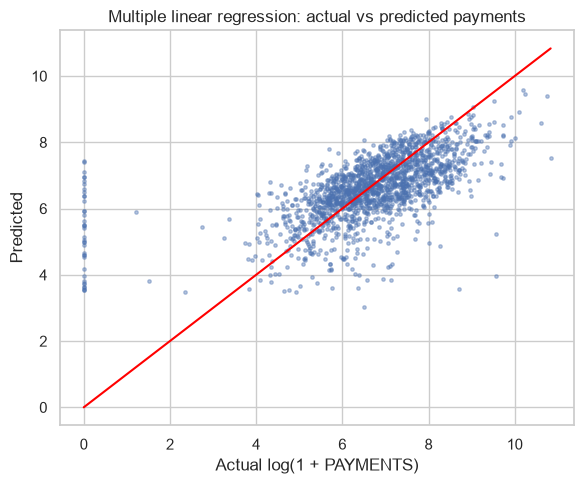

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

reg_features = ["BALANCE", "PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PURCHASES_FREQUENCY", "PRC_FULL_PAYMENT"]
y_reg = X_log["PAYMENTS"]
X_reg = X_log[reg_features]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)

lin = LinearRegression().fit(Xr_tr, yr_tr)
pred = lin.predict(Xr_te)
print("Model A (6 features):   R2 = %.3f, RMSE = %.3f, MAE = %.3f" % (
    r2_score(yr_te, pred), np.sqrt(mean_squared_error(yr_te, pred)), mean_absolute_error(yr_te, pred)))
print("5-fold CV R2: %.3f" % cross_val_score(LinearRegression(), X_reg, y_reg, cv=5, scoring="r2").mean())

coef = pd.Series(lin.coef_, index=reg_features).round(3)
display(coef.to_frame("Coefficient (effect on log PAYMENTS)"))

# Model B: add the segment (one-hot encoded)
X_reg_seg = pd.concat([X_reg, pd.get_dummies(df["Segment_Name"], drop_first=True).astype(float)], axis=1)
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(X_reg_seg, y_reg, test_size=0.2, random_state=RANDOM_STATE)
lin_b = LinearRegression().fit(Xb_tr, yb_tr)
pred_b = lin_b.predict(Xb_te)
print("Model B (+ segment):    R2 = %.3f, RMSE = %.3f, MAE = %.3f" % (
    r2_score(yb_te, pred_b), np.sqrt(mean_squared_error(yb_te, pred_b)), mean_absolute_error(yb_te, pred_b)))

plt.figure(figsize=(6, 5))
plt.scatter(yr_te, pred, s=6, alpha=0.4)
lims = [min(yr_te.min(), pred.min()), max(yr_te.max(), pred.max())]
plt.plot(lims, lims, color="red")
plt.xlabel("Actual log(1 + PAYMENTS)")
plt.ylabel("Predicted")
plt.title("Multiple linear regression: actual vs predicted payments")
plt.tight_layout()
plt.savefig("outputs/14_regression_actual_vs_predicted.png", dpi=120)
plt.show()

**Reading the result.** Model A explains about 37% of the variation in log payments (R-squared 0.37; 5-fold CV 0.35), a moderate result.
The coefficients show direction: a higher balance, a higher credit limit and more purchases go with higher payments, and the share of months paid in full has by far the largest coefficient.
Model B, which adds the segment, rises to R-squared 0.40, so the segments add a little useful information beyond the raw numbers.
Linear regression assumes straight-line relationships, so it cannot capture everything; it is a baseline, not the final answer.

## 19. Time series: ARIMA and SARIMA (Time Series Modeling with ARIMA and SARIMA)
**Important and honest:** the dataset has no dates, only a single snapshot per customer (`TENURE` is a count of months, not a time series).
So this section uses a **synthetic (simulated) monthly series** of average purchases for the *Premium Big Spenders* segment,
built from that segment's real average purchases, plus a yearly festive-season pattern, a small trend and random noise.
It shows **how** ARIMA and SARIMA would be used if the bank gave us monthly data. The forecast numbers are **not real findings**.

ADF stationarity test p-value (raw series): 0.800  (p > 0.05 suggests non-stationary, so differencing d=1 is used)
ARIMA(1,1,1)               RMSE on last 6 months: 1126.7
SARIMA(1,0,1)(1,1,0,12)    RMSE on last 6 months: 181.2


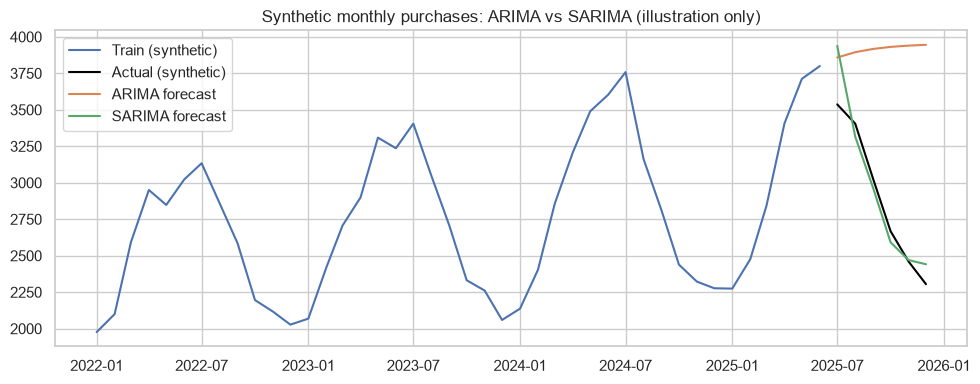

In [32]:
rng = np.random.default_rng(RANDOM_STATE)
base = df.loc[df["Segment_Name"] == "Premium Big Spenders", "PURCHASES"].mean()
months = pd.date_range("2022-01-01", periods=48, freq="MS")
season = 1 + 0.25 * np.sin(2 * np.pi * (months.month - 3) / 12)          # yearly cycle, peaks in the festive months
trend = np.linspace(0.9, 1.1, len(months))
series = pd.Series(base * season * trend * (1 + rng.normal(0, 0.04, len(months))), index=months, name="avg_purchases")
train, test = series[:-6], series[-6:]

try:
    from statsmodels.tsa.arima.model import ARIMA
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.stattools import adfuller

    print("ADF stationarity test p-value (raw series): %.3f  (p > 0.05 suggests non-stationary, so differencing d=1 is used)" % adfuller(train)[1])
    arima = ARIMA(train, order=(1, 1, 1)).fit()
    sarima = SARIMAX(train, order=(1, 0, 1), seasonal_order=(1, 1, 0, 12)).fit(disp=False)
    f_arima, f_sarima = arima.forecast(6), sarima.forecast(6)
    rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
    print("ARIMA(1,1,1)               RMSE on last 6 months: %.1f" % rmse(test, f_arima))
    print("SARIMA(1,0,1)(1,1,0,12)    RMSE on last 6 months: %.1f" % rmse(test, f_sarima))

    plt.figure(figsize=(10, 4))
    plt.plot(train.index, train, label="Train (synthetic)")
    plt.plot(test.index, test, label="Actual (synthetic)", color="black")
    plt.plot(test.index, f_arima, label="ARIMA forecast")
    plt.plot(test.index, f_sarima, label="SARIMA forecast")
    plt.title("Synthetic monthly purchases: ARIMA vs SARIMA (illustration only)")
    plt.legend()
    plt.tight_layout()
    plt.savefig("outputs/15_arima_sarima_forecast.png", dpi=120)
    plt.show()
except ImportError:
    print("statsmodels is not installed. Run:  pip install statsmodels   and re-run this cell.")

**Reading the result.** SARIMA adds a seasonal part (a 12-month cycle), so it should follow a repeating yearly pattern better than plain ARIMA.
With real data the steps would be the same: check stationarity, difference if needed, fit, forecast, and compare on a held-out period.

## 20. Deep learning: a multi-layer neural network (Introduction to Deep Learning; Deep Learning Architectures and Training)
A feed-forward neural network with two hidden layers (64 and 32 neurons, ReLU activation) is trained with the Adam optimiser
to predict the segment, using scikit-learn's `MLPClassifier`, so no GPU or TensorFlow is needed.
Key ideas shown: layers and activations, training by minimising a loss over many epochs, early stopping to avoid overfitting,
and reading the loss curve.

Neural network test accuracy: 0.988 (stopped after 27 epochs)
Neural network 5-fold CV accuracy: 0.986


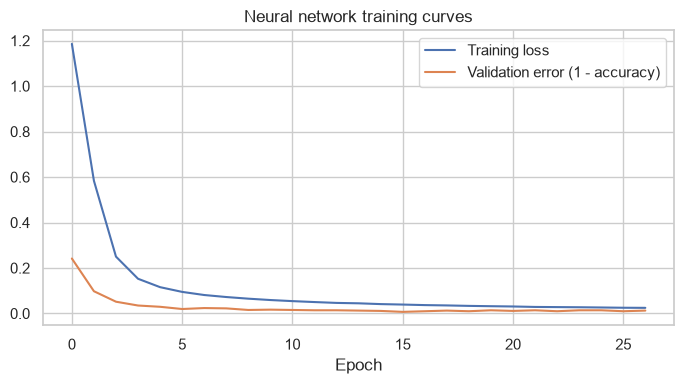

In [33]:
from sklearn.neural_network import MLPClassifier

mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam", max_iter=300,
                    early_stopping=True, validation_fraction=0.1, random_state=RANDOM_STATE)
mlp.fit(Xs_tr, ys_tr)
mlp_pred = mlp.predict(Xs_te)
print("Neural network test accuracy: %.3f (stopped after %d epochs)" % (accuracy_score(ys_te, mlp_pred), mlp.n_iter_))
print("Neural network 5-fold CV accuracy: %.3f" % cross_val_score(
    MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
    X_scaled, y, cv=skf).mean())

plt.figure(figsize=(7, 4))
plt.plot(mlp.loss_curve_, label="Training loss")
plt.plot(1 - np.array(mlp.validation_scores_), label="Validation error (1 - accuracy)")
plt.xlabel("Epoch")
plt.legend()
plt.title("Neural network training curves")
plt.tight_layout()
plt.savefig("outputs/16_neural_network_training.png", dpi=120)
plt.show()

**Reading the result.** The network reaches accuracy similar to the other classifiers, but it is harder to explain than a decision tree or logistic regression.
On a small tabular dataset like this one a neural network is not needed, but it shows the full workflow (layers, loss curve, early stopping).
Deeper architectures such as CNNs (images) and RNNs/transformers (text, sequences) need image or text data, which this project does not have.

## 21. NLP: turning customer behaviour into text and classifying it (Intro to NLP; Advanced NLP Techniques)
**Honest note:** there is no real text in the dataset. So each customer is described by a **short sentence generated from their own real numbers**
(for example "very high purchases, no cash advance, pays in full rarely"). This text is *derived from the same features*, so it is a demonstration of
the NLP workflow (tokens, n-grams, TF-IDF, a text classifier), not a finding from real customer text.

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer

def level(series, words):
    """Turn a numeric column into words using its quartiles (low ... high)."""
    cuts = series.rank(pct=True, method="first")
    return pd.cut(cuts, bins=[0, 0.25, 0.5, 0.75, 1.0], labels=words, include_lowest=True).astype(str)

lv = ["low", "moderate", "high", "very high"]
text = ("purchases " + level(df["PURCHASES"], lv) + " balance " + level(df["BALANCE"], lv) +
        " cashadvance " + level(df["CASH_ADVANCE"], lv) + " installments " + level(df["INSTALLMENTS_PURCHASES"], lv) +
        " payfull " + level(df["PRC_FULL_PAYMENT"], lv))
df["Behaviour_Text"] = text
print(df["Behaviour_Text"].head(3).to_string())

vec = TfidfVectorizer(ngram_range=(1, 2), stop_words=None, min_df=5)
Xt = vec.fit_transform(df["Behaviour_Text"])
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split(Xt, df["Segment"], test_size=0.2, stratify=df["Segment"], random_state=RANDOM_STATE)
nlp_clf = LogisticRegression(max_iter=2000).fit(Xt_tr, yt_tr)
print("Text classifier (TF-IDF + Logistic Regression) test accuracy: %.3f" % accuracy_score(yt_te, nlp_clf.predict(Xt_te)))

terms = np.array(vec.get_feature_names_out())
for seg_id, name in segment_names.items():
    top = terms[np.argsort(nlp_clf.coef_[list(nlp_clf.classes_).index(seg_id)])[-4:][::-1]]
    print(f"{name:<25} top words: {', '.join(top)}")

0    purchases moderate balance low cashadvance low...
1    purchases low balance very high cashadvance ve...
2    purchases high balance very high cashadvance l...
Text classifier (TF-IDF + Logistic Regression) test accuracy: 0.818
Installment Buyers        top words: installments very, high payfull, payfull very, cashadvance moderate
High-Balance Revolvers    top words: cashadvance very, high installments, high, balance very
Premium Big Spenders      top words: purchases very, high balance, low installments, cashadvance low
Cash-Advance Dependents   top words: purchases low, low balance, cashadvance very, high installments
Dormant / Low Activity    top words: balance low, low cashadvance, low, moderate installments


**Reading the result.** The text classifier reaches about 82% accuracy, lower than the numeric models because turning numbers into four words (low ... very high) throws away detail.
The top words per segment match the business meaning (for example "purchases low" and "cashadvance very" for Cash-Advance Dependents, "installments very" for Installment Buyers), which is a useful sanity check.
With real customer comments or complaint text the same pipeline (clean, tokenise, TF-IDF, classify) would apply.

## 21b. REAL data: forecasting daily credit card complaints with ARIMA and SARIMA (Time Series Modeling with ARIMA and SARIMA)
**This section uses real data.** `complaints.csv` is an export from the US CFPB Consumer Complaint Database (product = Credit card, 19 Aug to 19 Nov 2026, 24,990 complaints).
Each complaint has a received date, so counting complaints per day gives a **real time series**.
It is a different dataset from the customer file, so it does not describe our 8,950 customers. It shows ARIMA/SARIMA on real, dated credit card data.
**Data caveat:** counts for the most recent days are low because complaints are published with a delay. The last 14 days are therefore left out of the modelling.

Days: 79 | average per weekday: 347 | per weekend day: 178
Seasonal-naive baseline (same weekday last week) RMSE on last 14 days: 40.4
ADF test p-value (raw series): 0.980


c:\Users\SHRIDHAR\Downloads\credit-card-segmentation 4\venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA(1,1,1)                RMSE on last 14 days: 126.0
SARIMA(1,0,1)(1,1,1,7)      RMSE on last 14 days: 28.3


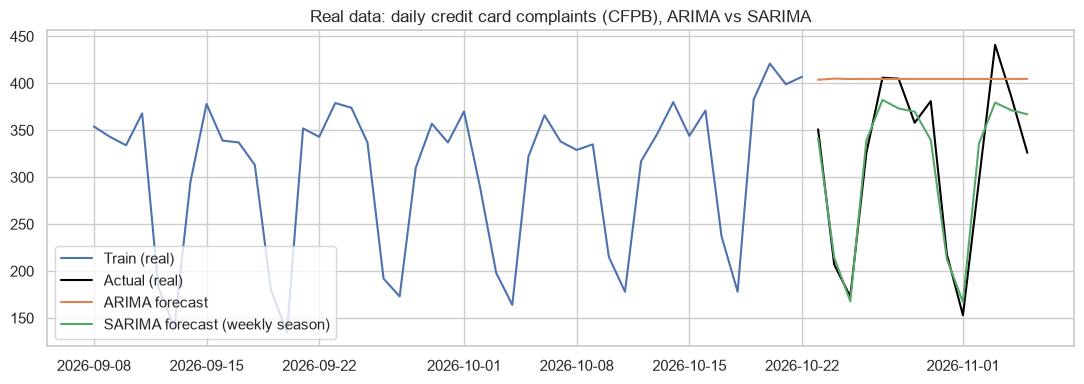

In [35]:
cmp_raw = pd.read_csv("complaints.csv")
daily = (pd.to_datetime(cmp_raw["Date received"], utc=True).dt.tz_localize(None).dt.normalize()
         .value_counts().sort_index().asfreq("D", fill_value=0))
daily = daily[:"2026-11-05"]                                   # drop the incomplete (not yet published) tail
print("Days:", len(daily), "| average per weekday: %.0f | per weekend day: %.0f" %
      (daily[daily.index.dayofweek < 5].mean(), daily[daily.index.dayofweek >= 5].mean()))
r_train, r_test = daily[:-14], daily[-14:]

# Baseline that needs no library: "same weekday last week"
naive = r_train[-7:].values.tolist() * 2
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
print("Seasonal-naive baseline (same weekday last week) RMSE on last 14 days: %.1f" % rmse(r_test, naive))

try:
    from statsmodels.tsa.arima.model import ARIMA
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    from statsmodels.tsa.stattools import adfuller

    print("ADF test p-value (raw series): %.3f" % adfuller(r_train)[1])
    arima = ARIMA(r_train, order=(1, 1, 1)).fit()
    sarima = SARIMAX(r_train, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7)).fit(disp=False)
    f_a, f_s = arima.forecast(14), sarima.forecast(14)
    print("ARIMA(1,1,1)                RMSE on last 14 days: %.1f" % rmse(r_test, f_a))
    print("SARIMA(1,0,1)(1,1,1,7)      RMSE on last 14 days: %.1f" % rmse(r_test, f_s))

    plt.figure(figsize=(11, 4))
    plt.plot(r_train.index[-45:], r_train[-45:], label="Train (real)")
    plt.plot(r_test.index, r_test, label="Actual (real)", color="black")
    plt.plot(r_test.index, f_a, label="ARIMA forecast")
    plt.plot(r_test.index, f_s, label="SARIMA forecast (weekly season)")
    plt.title("Real data: daily credit card complaints (CFPB), ARIMA vs SARIMA")
    plt.legend()
    plt.tight_layout()
    plt.savefig("outputs/17_real_complaints_arima.png", dpi=120)
    plt.show()
except ImportError:
    print("statsmodels is not installed. Run:  python -m pip install statsmodels   and re-run this cell.")

**Reading the result.** The real series has a clear **weekly pattern**: about 347 complaints on an average weekday and only about 178 on a weekend day.
Plain ARIMA has no seasonal part, so it cannot follow that weekly zig-zag. SARIMA with a 7-day season can, so it should have the lower error.
The baseline "same weekday last week" is a useful yardstick: a model is only worth using if it beats it.

## 21c. REAL data: NLP on complaint text (Intro to NLP; Advanced NLP Techniques)
**This section uses real text.** Each CFPB complaint carries the issue and sub-issue chosen by the consumer, for example
*"Problem with a purchase shown on your statement. Credit card company isn't resolving a dispute about a purchase on your statement."*
The long free-text narrative is not in this export, so the text here is short. The workflow is the standard NLP one: clean, TF-IDF, then (1) **cluster** the text and (2) **classify** the company outcome.

In [36]:
from sklearn.metrics import roc_auc_score, f1_score

nlp = cmp_raw[~cmp_raw["Company response to consumer"].isin(["In progress", "Untimely response"])].copy()
nlp["text"] = (nlp["Issue"].fillna("") + ". " + nlp["Sub-issue"].fillna("")).str.lower()
nlp["outcome"] = np.where(nlp["Company response to consumer"].str.contains("relief"), "Relief", "Explanation only")
print("Complaints used:", len(nlp), "| share that got relief: %.1f%%" % (100 * (nlp["outcome"] == "Relief").mean()))

# (1) Unsupervised: cluster the complaint text (same idea as our customer segmentation, but on words)
vec_c = TfidfVectorizer(ngram_range=(1, 2), min_df=5, stop_words="english")
Xc = vec_c.fit_transform(nlp["text"])
nlp["Text_Cluster"] = KMeans(6, n_init=10, random_state=RANDOM_STATE).fit_predict(Xc)
summary = nlp.groupby("Text_Cluster").agg(complaints=("outcome", "size"),
                                         relief_rate=("outcome", lambda s: round(100 * (s == "Relief").mean(), 1)),
                                         main_issue=("Issue", lambda s: s.value_counts().index[0]))
display(summary)

# (2) Supervised: can the complaint text predict whether the company gave relief?
vec_t = TfidfVectorizer(ngram_range=(1, 2), min_df=5)
Xr = vec_t.fit_transform(nlp["text"])
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, nlp["outcome"], test_size=0.2, stratify=nlp["outcome"], random_state=RANDOM_STATE)
clf_r = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xr_tr, yr_tr)
proba = clf_r.predict_proba(Xr_te)[:, list(clf_r.classes_).index("Relief")]
print("ROC-AUC (0.5 = guessing): %.3f | F1 for 'Relief': %.3f" %
      (roc_auc_score(yr_te == "Relief", proba), f1_score(yr_te, clf_r.predict(Xr_te), pos_label="Relief")))
terms_r = np.array(vec_t.get_feature_names_out())
order = np.argsort(clf_r.coef_[0])
print("Words linked to RELIEF:           ", ", ".join(terms_r[order[-6:]][::-1]))
print("Words linked to EXPLANATION only: ", ", ".join(terms_r[order[:6]]))

Complaints used: 20039 | share that got relief: 26.7%


,complaints,relief_rate,main_issue
Text_Cluster,,,
0,5552,22.5,Getting a credit card
1,1407,34.1,Problem with a purchase shown on your statement
2,5577,26.8,Problem with a purchase shown on your statement
3,3217,30.5,"Other features, terms, or problems"
4,1960,35.5,Fees or interest
5,2326,19.5,Closing your account


ROC-AUC (0.5 = guessing): 0.605 | F1 for 'Relief': 0.435
Words linked to RELIEF:            fees, and services, add, products and, on products, add on
Words linked to EXPLANATION only:  application, denied, card application, application denied, your credit, account information


**Reading the result.** The text clusters are readable (card applications, disputes on purchases, fees and interest, closing an account, and so on) and they have **different relief rates**
(roughly 20% for some clusters and 35% for others), so the wording of a complaint carries some information about the outcome.
The classifier is only a **weak** predictor (ROC-AUC about 0.60, where 0.5 is guessing), which is expected: the outcome depends on facts that are not in two short phrases. This is an honest result, not a failure.
Words such as *application denied* point to "explanation only", while *fees* and *add-on products* point to relief.
With the full complaint narrative the same pipeline would work on much richer text.

## 22. Generative AI and LLMs: prompts, evaluation and fine-tuning (Intro to GenAI, Transformers & LLMs; Training and Fine-tuning LLMs; Advanced Fine-tuning and Model Evaluation)
**What is done here (and what is not).** Large language models are *used*, not trained, in this project:
1. **Prompt engineering:** a prompt template is filled with each segment's real profile, so an LLM can draft a marketing message.
2. **Evaluation:** a simple automatic check (length, banned words, mentions the segment's focus) plus a human checklist.
3. **Fine-tuning:** explained in words only. No model is trained here because that needs labelled text examples and GPU time that this project does not have.
The notebook does **not** call an LLM by itself. The prompts are saved to `outputs/llm_prompts.txt`; paste one into any LLM (Claude, ChatGPT, Gemini).

In [37]:
action_focus = {
    "Premium Big Spenders": "rewards, a premium card and a higher credit limit",
    "Installment Buyers": "EMI offers and cashback on instalments",
    "High-Balance Revolvers": "balance-transfer and repayment plans",
    "Cash-Advance Dependents": "financial counselling and a gentle repayment plan (not new credit)",
    "Dormant / Low Activity": "a welcome-back offer to restart using the card",
}
PROMPT = ("You are a marketing assistant at a bank. Write a short, friendly, compliant SMS (max 40 words) for customers in the segment "
          "'{segment}'. Facts about this segment: average purchases {purchases:.0f}, average cash advance {cash:.0f}, average balance {balance:.0f}. "
          "Focus on: {focus}. Do not promise guaranteed approval and do not mention other customers.")
prompts = []
for sid, name in segment_names.items():
    row = profile.loc[sid]
    prompts.append(PROMPT.format(segment=name, purchases=row["PURCHASES"], cash=row["CASH_ADVANCE"],
                                 balance=row["BALANCE"], focus=action_focus[name]))
with open("outputs/llm_prompts.txt", "w", encoding="utf-8") as f:
    f.write("\n\n".join(prompts))
print(prompts[2])

# Simple automatic evaluation of an LLM answer (used after pasting the model's reply)
BANNED = ["guaranteed", "free money", "no risk", "100% approval"]
def check_message(text, max_words=40):
    words = len(text.split())
    problems = []
    if words > max_words: problems.append(f"too long ({words} words)")
    problems += [f"banned phrase: {b}" for b in BANNED if b in text.lower()]
    return "PASS" if not problems else "FAIL: " + "; ".join(problems)

example = "Hi! Enjoy more rewards on every purchase. Ask us about a premium card with a higher limit. Terms apply."
print("Example check ->", check_message(example))
print("Bad example   ->", check_message("Guaranteed approval! Free money for you!"))

You are a marketing assistant at a bank. Write a short, friendly, compliant SMS (max 40 words) for customers in the segment 'Premium Big Spenders'. Facts about this segment: average purchases 2769, average cash advance 46, average balance 1479. Focus on: rewards, a premium card and a higher credit limit. Do not promise guaranteed approval and do not mention other customers.
Example check -> PASS
Bad example   -> FAIL: banned phrase: guaranteed; banned phrase: free money


**Example of what an LLM can return** (written by Claude, an LLM, from the prompt above; shown only as an illustration of the idea):
- *Premium Big Spenders:* "Thank you for being a valued customer. Enjoy extra rewards and ask us about a premium card with a higher limit. Terms apply."
- *Cash-Advance Dependents:* "We are here to help. Talk to our team about a simple repayment plan that fits your budget. No pressure, no judgement."

**Evaluating LLM output (human checklist):** is it factually consistent with the segment profile? is the tone respectful? does it avoid promises the bank cannot keep?
does it follow the length limit? **Fine-tuning (concept):** you would collect many (prompt, ideal message) pairs approved by the marketing team and train a model on them,
using parameter-efficient methods such as LoRA. This improves tone and consistency, but good prompting is enough for this project.

## 23. Excel and Power BI exports (Excel, Power BI)
- An Excel workbook with the profile, the comparison and the labelled customers (use it to build pivot tables, as taught in Advanced Excel).
- A clean CSV for Power BI or Tableau (`powerbi_tableau_data.csv`) with segment names and the main fields.

In [38]:
with pd.ExcelWriter("outputs/segmentation_results.xlsx", engine="openpyxl") as xl:
    comparison.to_excel(xl, sheet_name="Algorithm comparison", index=False)
    profile.rename(index=segment_names).to_excel(xl, sheet_name="Segment profile")
    df.to_excel(xl, sheet_name="Customers + segment", index=False)

bi = df[["CUST_ID", "Segment", "Segment_Name", "BALANCE", "PURCHASES", "ONEOFF_PURCHASES",
         "INSTALLMENTS_PURCHASES", "CASH_ADVANCE", "CREDIT_LIMIT", "PAYMENTS", "MINIMUM_PAYMENTS",
         "PURCHASES_FREQUENCY", "CASH_ADVANCE_FREQUENCY", "PRC_FULL_PAYMENT", "TENURE"]].copy()
bi["PCA_1"], bi["PCA_2"] = X_pca[:, 0], X_pca[:, 1]
bi.to_csv("outputs/powerbi_tableau_data.csv", index=False)
print("Saved Excel workbook and BI CSV")

Saved Excel workbook and BI CSV


## 24. Save the model for deployment (Gradio chatbot / app deployment)
The scaler, K-Means model and default values are saved so `app_gradio.py` can assign a segment to a new customer.

In [39]:
import joblib, json
os.makedirs("models", exist_ok=True)
final_scaler = StandardScaler().fit(X_log)
final_km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(final_scaler.transform(X_log))
assert (final_km.labels_ == models["K-Means"]).all(), "Refit does not match the final segments"
joblib.dump({"scaler": final_scaler, "kmeans": final_km, "columns": list(X.columns),
             "segment_names": segment_names}, "models/segmentation_model.joblib")
json.dump(X.median().to_dict(), open("models/feature_medians.json", "w"), indent=1)
print("Saved models/segmentation_model.joblib")

Saved models/segmentation_model.joblib
